# PW7 - Encoding, System Design and Debugging

**Team:** Noé Berdoz, Michael Strefeler

Our starting levels, the time spent per exercise and the bonus request are in the preamble of `ex1-analysis.ipynb`.

For this exercise we felt like it made the most sense to keep the provided code and to do all of the steps below it.

In [1]:
import numpy as np
import pandas as pd

from sklearn import metrics
from sklearn import model_selection
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import Binarizer, LabelEncoder, MaxAbsScaler, MinMaxScaler, OneHotEncoder, \
    OrdinalEncoder, RobustScaler, StandardScaler

# Exercise 2 - Debugging - Drugs

The dataset contains a set of patients, all of whom suffered from the same illness.
During their course of treatment, each patient responded to one of 5 medications: Drug A, Drug B, Drug c, Drug x or y.

This complex dataset proposes a set of challenges that you'll try to overcome. A basic ML pipeline is already in place. You have to optimize the performance of the model by applying good practices, debugging pre-processing errors, etc.

**Rules**:
- Do not use other modules than those already imported *(or do it only if your own code is not working. In this case, keep your own code in the notebook, commented, so that we know what you tried)*.
- Explain **all** of your choices. For every task, choose the most appropriate option for this problem and describe your choice.
- You can modify any parts of the code or replace the model by one already used in previous PWs.

**Work to do**:
- [x] Apply a type of normalization.
- [x] Encode categorical data.
- [x] Use all columns in the dataset (or choose the most meaningful features).
- [x] Choose a more appropriate metric.
- [x] Optimize hyper-parameters.
- [x] Test the model performance correctly using a separated test set.
- Apply **two** of those techniques:
  - [x] Keep relative class frequencies in the train/test sets (check train_test_split docs)
  - [ ] Show which feature(s) are the most correlated to the target.
  - [x] Use cross-validation.

In [2]:
df = pd.read_csv("drug.csv")
df.head()

,age,sex,bp,cholesterol,Na_to_K,drug
0,23,F,HIGH,HIGH,25.355,drugY
1,47,M,LOW,HIGH,13.093,drugC
2,47,M,LOW,HIGH,10.114,drugC
3,28,F,NORMAL,HIGH,7.798,drugX
4,61,F,LOW,HIGH,18.043,drugY


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   age          200 non-null    int64  
 1   sex          200 non-null    str    
 2   bp           200 non-null    str    
 3   cholesterol  200 non-null    str    
 4   Na_to_K      200 non-null    float64
 5   drug         200 non-null    str    
dtypes: float64(1), int64(1), str(4)
memory usage: 9.5 KB


In [4]:
categorical_columns = ["sex", "bp", "cholesterol", "drug"]

# TODO: you will replace this by a more adapted preprocessing step
df = df.drop(columns=["sex", "bp", "cholesterol"])

In [5]:
X = df.drop(columns="drug")
y = df["drug"]

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [7]:
# TODO: preprocessing / encoding / normalization are likely missing here...

In [8]:
# removed "." after KNeighborsClassifier(100) which was causing a syntax error
knn = KNeighborsClassifier(100)  # you may change the classifier if you want, or tune its hyperparameters
knn.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",100
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[object](5,)","['drugA','drugB','drugC','drugX','drugY']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [9]:
# fixed bug with this function where estimator was never used
def predict(estimator, X, y):
    # predict
    y_pred = estimator.predict(X)
    
    # show confusion matrix
    cm = confusion_matrix(y, y_pred)
    disp=ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=estimator.classes_)
    disp.plot()
    
    # check metric (this one is probably not the best choice...)
    metric = metrics.accuracy_score(y, y_pred)
    print(f"Accuracy: {metric}")

Accuracy: 0.49375


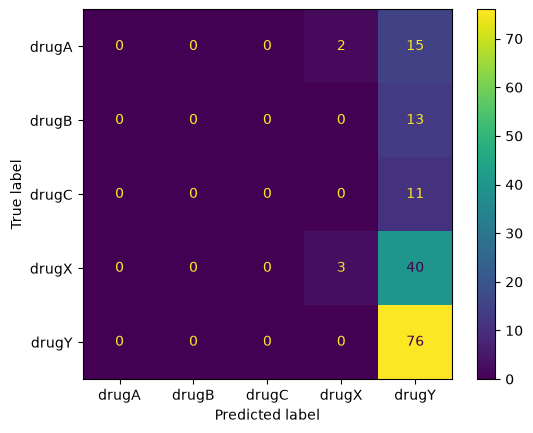

In [10]:
predict(knn, X_train, y_train)

In [11]:
# TODO: Adapt the code above to your needs according to the problems you identify. A good way to 
# do it would be to tell us a story, starting from a baseline system and improving it step by step.
# E.g.: system A = baseline, system B = system A + preprocessing, system C = system B + hyperparameter tuning, etc.

The baseline system/system A's code has been mostly untouched and is above this cell, a few bugs were fixed. It's pretty obvious that the system isn't performing very well (this might be the worst confusion matrix that we've ever seen).

System A predicted drugY for 155 out of 160 times on the training set.

As mentioned in the instructions, this system could really use some pre-processing and hyperparameter tuning.

Here are major mistakes from system A that will be fixed with systems B and C:
- categorical data is ignored instead of being encoded
- no normalization whatsoever
- no hyperparameter tuning
- the model is never evaluated on the test set
- accuracy isn't a very good metric for the problem

Before any pre-processing, it's always a good idea to do an EDA. We already know that the dataset contains 3 columns with categorical data: sex, bp (blood pressure), and cholesterol.

In [12]:
df = pd.read_csv("drug.csv")
df.head()

,age,sex,bp,cholesterol,Na_to_K,drug
0,23,F,HIGH,HIGH,25.355,drugY
1,47,M,LOW,HIGH,13.093,drugC
2,47,M,LOW,HIGH,10.114,drugC
3,28,F,NORMAL,HIGH,7.798,drugX
4,61,F,LOW,HIGH,18.043,drugY


array([[<Axes: title={'center': 'age'}>,
        <Axes: title={'center': 'Na_to_K'}>]], dtype=object)

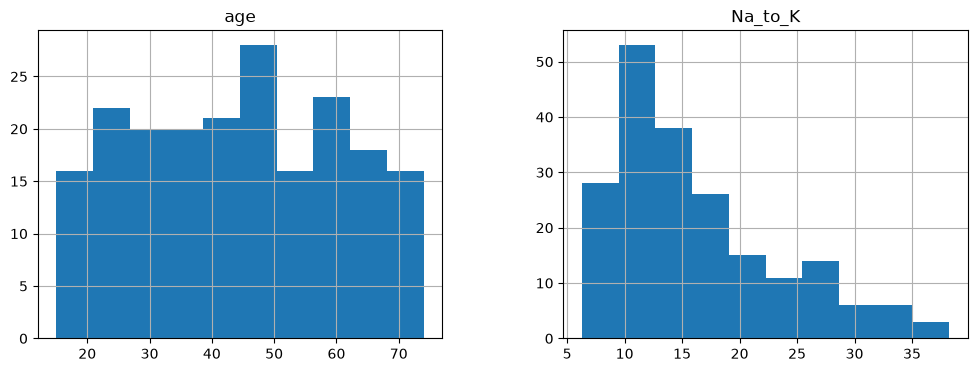

In [13]:
df.hist(figsize=(12, 4))

In [14]:
print(df['sex'].value_counts(),"\n")
print(df['bp'].value_counts(),"\n")
print(df['cholesterol'].value_counts(),"\n")
print(df['drug'].value_counts())

sex
M    104
F     96
Name: count, dtype: int64 

bp
HIGH      77
LOW       64
NORMAL    59
Name: count, dtype: int64 

cholesterol
HIGH      103
NORMAL     97
Name: count, dtype: int64 

drug
drugY    91
drugX    54
drugA    23
drugC    16
drugB    16
Name: count, dtype: int64


## System B

The baseline or System A + pre-processing. The provided code is what we'll call System A which is our baseline.

Now we can pre-process the data because the data has been understood better. The first step is to encode the categorical data. We'll use a One-hot encoder for sex because it's nominal data. Ordinal encoders for blood pressure and cholesterol which both are ordinal Low, Normal, High and Normal, High. For the drug column we'll use a label encoder since it corresponds to the class label that we are trying to predict.

In [15]:
better_df = df.copy()
one_hot = OneHotEncoder(drop="if_binary", sparse_output=False, dtype=int)
better_df["sex"] = one_hot.fit_transform(better_df[["sex"]]).ravel()

bp_encoder = OrdinalEncoder(categories=[["LOW", "NORMAL", "HIGH"]])
better_df["bp"] = bp_encoder.fit_transform(better_df[["bp"]]).astype(int)

chol_encoder = OrdinalEncoder(categories=[["NORMAL", "HIGH"]])
better_df["cholesterol"] = chol_encoder.fit_transform(better_df[["cholesterol"]]).astype(int)

le = LabelEncoder()
better_df["drug"] = le.fit_transform(better_df["drug"])

better_df.head()

,age,sex,bp,cholesterol,Na_to_K,drug
0,23,0,2,1,25.355,4
1,47,1,0,1,13.093,2
2,47,1,0,1,10.114,2
3,28,0,1,1,7.798,3
4,61,0,0,1,18.043,4


Now we can plot some histograms to get an even better idea of the data

array([[<Axes: title={'center': 'age'}>, <Axes: title={'center': 'sex'}>],
       [<Axes: title={'center': 'bp'}>,
        <Axes: title={'center': 'cholesterol'}>],
       [<Axes: title={'center': 'Na_to_K'}>,
        <Axes: title={'center': 'drug'}>]], dtype=object)

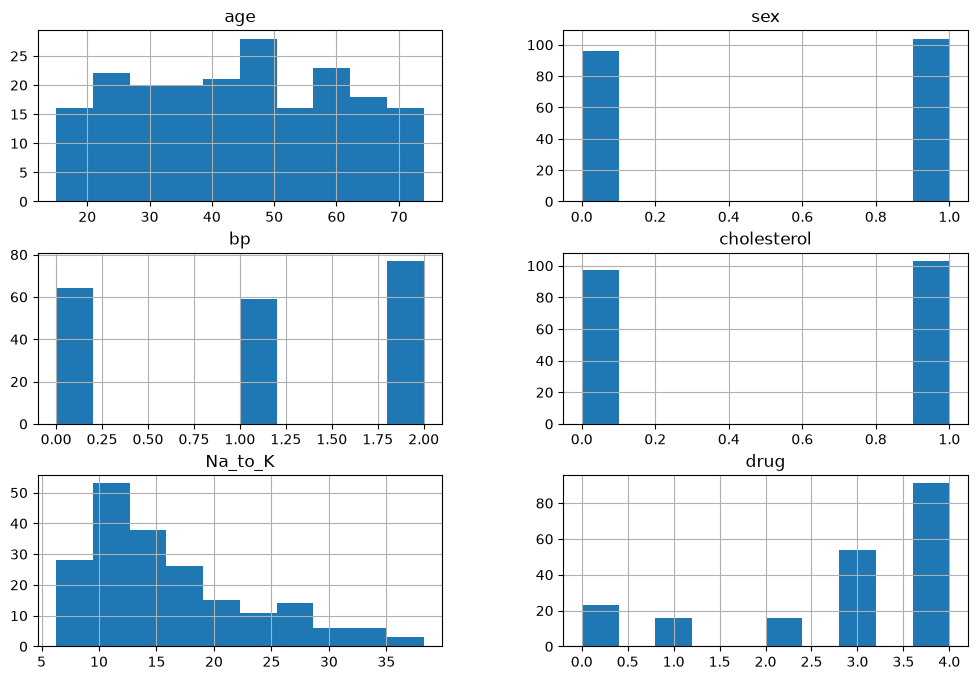

In [16]:
better_df.hist(figsize=(12,8))

This allows us to check that sex got separated in two values 0 or 1; bp is either 0, 1 or 2 which correspond to Low, normal, high; cholesterol is either 0 or 1 (normal or high); drug has 5 classes (A, B, C, X, Y).

In [17]:
X_b = better_df.drop(columns="drug")
y_b = better_df["drug"]

The code below splits the data in train and test sets while keeping the relative class frequencies using `stratify=y_b`

In [18]:
X_train, X_test, y_train, y_test = train_test_split(X_b, y_b, test_size=0.2, random_state=42, stratify=y_b)

We used StratifiedKFold for our cross-validation and normalized the data in the for loop. The x_min and x_max should only be computed on the training set. Computing them on the whole data set (including the test set) is considered as "cheating". That's why in the loop X_tr uses scaler.fit_transform(...), but X_val(the test set of the fold) uses scaler.transform(...).

In [19]:
cols = ["age", "Na_to_K", "bp"]
skf = model_selection.StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scores = []
for train_idx, val_idx in skf.split(X_train, y_train):
    X_tr = X_train.iloc[train_idx].copy()
    X_val = X_train.iloc[val_idx].copy()
    y_tr = y_train.iloc[train_idx]
    y_val = y_train.iloc[val_idx]

    scaler = MinMaxScaler()
    X_tr[cols] = scaler.fit_transform(X_tr[cols])   # fit on this fold's training part only
    X_val[cols] = scaler.transform(X_val[cols])     # transform only

    knn = KNeighborsClassifier(100) # Same classifier as system A
    knn.fit(X_tr, y_tr)
    scores.append(metrics.accuracy_score(y_val, knn.predict(X_val)))

print(f"CV accuracy: {np.mean(scores):.3f}")

CV accuracy: 0.456


In [20]:
X_train_s = X_train.copy()
X_test_s = X_test.copy()

scaler = MinMaxScaler()
X_train_s[cols] = scaler.fit_transform(X_train_s[cols])
X_test_s[cols] = scaler.transform(X_test_s[cols])

knn = KNeighborsClassifier(100)
knn.fit(X_train_s, y_train)
print(metrics.accuracy_score(y_test, knn.predict(X_test_s)))

0.45


Accuracy: 0.45


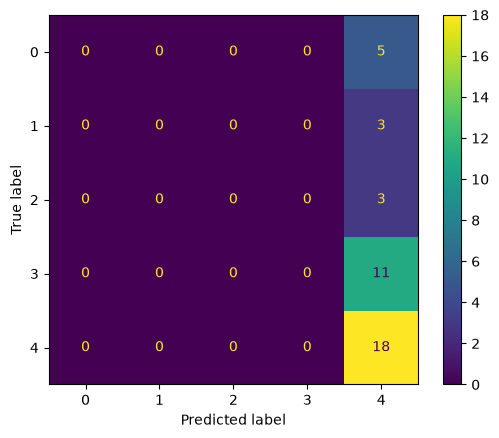

In [21]:
predict(knn, X_test_s, y_test)

System A and System B have pretty similar performances due to the fact that we didn't do any hyperparameter tuning.

A KNeighborsClassifier that uses n=100 when the dataset only has 200 rows can't perform miracles even when the data has been pre-processed.

## System C

System B + Hyperparameter tuning

We wrote the hyperparameter search by hand with ParameterGrid and a StratifiedKFold loop instead of using GridSearchCV, so that the scaler is refit on the training part of each fold only; scaling the whole training set beforehand would leak the validation folds' min and max into pre-processing. A Pipeline would normally solve this, but it is not among the allowed imports. We tune n_neighbors, weights and p, which are the number of neighbors, the weight function used in prediction, and the power parameter of the Minkowski metric (p = 1 is the Manhattan distance and p = 2 the Euclidean distance).

We also tune the scaler (MinMaxScaler, StandardScaler or RobustScaler), applied to age, Na_to_K and the ordinal bp so that all features have a comparable range in the distance computation.

We chose macro F1 as the scoring metric because it computes the F1 score of each class separately and then averages them with equal weight, so minority classes count as much as majority ones; accuracy, in contrast, can look good even if the model neglects the smaller classes.

In [22]:
cols = ["age", "Na_to_K", "bp"]

param_grid = {
    "scaler": [MinMaxScaler, StandardScaler, RobustScaler],
    "n_neighbors": [1, 3, 5, 7, 9, 11, 15],
    "weights": ["uniform", "distance"],
    "p": [1, 2],
}

skf = model_selection.StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Manual grid search: the scaler is fit on each fold's training part only,
# so no information from the validation fold leaks into pre-processing.
results = []
for params in model_selection.ParameterGrid(param_grid):
    knn_params = {k: v for k, v in params.items() if k != "scaler"}
    scaler_cls = params["scaler"]

    fold_scores = []
    for train_idx, val_idx in skf.split(X_train, y_train):
        X_tr = X_train.iloc[train_idx].copy()
        X_val = X_train.iloc[val_idx].copy()
        y_tr = y_train.iloc[train_idx]
        y_val = y_train.iloc[val_idx]

        scaler = scaler_cls()
        X_tr[cols] = scaler.fit_transform(X_tr[cols])   # fit on fold-train only
        X_val[cols] = scaler.transform(X_val[cols])     # transform only

        model = KNeighborsClassifier(**knn_params)
        model.fit(X_tr, y_tr)
        fold_scores.append(
            metrics.f1_score(y_val, model.predict(X_val), average="macro")
        )
    results.append((np.mean(fold_scores), params))

best_cv_score, best_params = max(results, key=lambda r: r[0])
best_scaler_cls = best_params["scaler"]
best_knn_params = {k: v for k, v in best_params.items() if k != "scaler"}

print(f"Best scaler: {best_scaler_cls.__name__}")
print(f"Best KNN params: {best_knn_params}")
print(f"Best CV macro F1: {best_cv_score:.4f}")

Best scaler: StandardScaler
Best KNN params: {'n_neighbors': 11, 'p': 1, 'weights': 'distance'}
Best CV macro F1: 0.9507


Now that we have our best parameters we can make predictions on the test set

In [23]:
# Final model: scaler fit on the full training set, test set only transformed
X_train_s_c, X_test_s_c = X_train.copy(), X_test.copy()
scaler = best_scaler_cls()
X_train_s_c[cols] = scaler.fit_transform(X_train_s_c[cols])
X_test_s_c[cols] = scaler.transform(X_test_s_c[cols])

best_knn = KNeighborsClassifier(**best_knn_params)
best_knn.fit(X_train_s_c, y_train)

y_pred = best_knn.predict(X_test_s_c)
print(f"Test macro F1: {metrics.f1_score(y_test, y_pred, average='macro'):.4f}")

Test macro F1: 0.8882


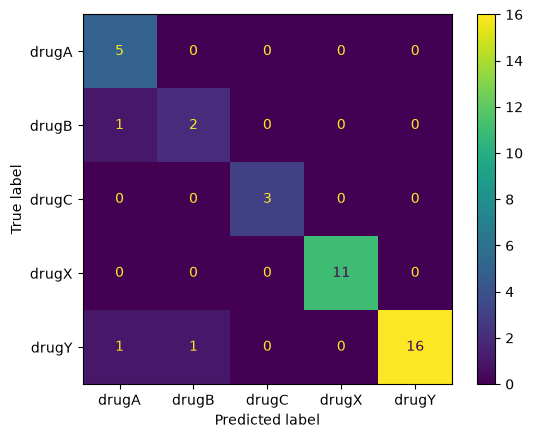

In [24]:
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=le.classes_).plot()

System C performs better than Systems A and B, and most of the improvement comes from hyperparameter tuning: System B, which only added preprocessing, was no better than the baseline because k = 100 is far too large for a dataset of 200 rows. Preprocessing is still necessary, since it lets the model use all the columns on a comparable scale, but it only pays off once the hyperparameters are tuned. The earlier outputs used different metrics (and A’s confusion matrix was computed on the training set), so the fairest comparison is the one below, where all three systems are evaluated on the same test set.

In [25]:
cols_base = ["age", "Na_to_K"]
knn_a = KNeighborsClassifier(100).fit(X_train[cols_base], y_train)   # baseline: no encoding, no scaling
systems = {
    "A (baseline)": (knn_a, X_test[cols_base]),
    "B (+ preprocessing)": (knn, X_test_s),          # the k=100 model fit on scaled data
    "C (+ tuning)": (best_knn, X_test_s_c),
}
for name, (model, X_eval) in systems.items():
    pred = model.predict(X_eval)
    print(f"{name}: acc={metrics.accuracy_score(y_test, pred):.4f}, "
          f"macro F1={metrics.f1_score(y_test, pred, average='macro'):.4f}")

A (baseline): acc=0.4500, macro F1=0.1241
B (+ preprocessing): acc=0.4500, macro F1=0.1241
C (+ tuning): acc=0.9250, macro F1=0.8882


As expected system C has a higher accuracy and macro F1 score than the other two systems. Accuracy of 0.925 and macro F1 of 0.8882 for system C vs accuracies of 0.45 and macro F1s of 0.1241 for systens A and B.